# 11 — Backtest 004.2: Rompimento da Ásia na conta Micro Ultra Low (EURUSD H1, walk-forward)

**De onde vem:** no 004.1, o rompimento da Ásia no H1 mostrou vantagem real antes dos custos (+0,105 R, PBO 0,12,
melhor que o acaso), mas o spread da conta **Standard** levou cerca de 80% dela (+0,020 R líquido, fator de lucro 1,04).

**O que muda:** tudo igual ao 004.1 (mesmas 128 combinações, mesmo walk-forward 36 + 6 meses, mesmos critérios), mas
com os **preços e o spread do símbolo `EURUSDm#`**, da conta **Micro Ultra Low** da XM:

| | Standard (004.1) | Micro Ultra Low (004.2) |
|---|---|---|
| Símbolo | `EURUSD` | `EURUSDm#` |
| Spread mediano 10h–15h (2023+) | 17 pontos (1,7 pip) | **9 pontos (0,9 pip)** |
| Comissão | não tem | não tem |
| Contrato | 100.000 (lote padrão) | 1.000 (micro lote) |

**Limitação importante:** o símbolo Ultra Low só existe desde **meados de 2018**. Usamos os **preços do Standard** (16 anos) com o
**spread registrado do Ultra Low** onde ele existe e **50% do spread do Standard** antes disso (a proporção observada
depois de 2019 fica entre 0,4 e 0,5). O bid do Ultra Low é sempre ~4 pontos acima do Standard (mesmo preço médio),
então essa diferença constante se anula entre entrada e saída. Por
isso a seção 9 mostra também o resultado **só de 2019 em diante**, onde o spread é o real.

**Regras do setup (iguais ao 004):**

| Item | Regra |
|---|---|
| Faixa asiática | Máxima e mínima entre **00h e 10h** do servidor (ou 03h–10h, como variação) |
| Abertura de Londres | **10h do servidor** = 8h em Londres, o ano todo (os dois mudam de horário juntos) |
| Entrada | **Ordem stop** 1 pip acima da máxima / abaixo da mínima (o clássico) **ou** só quando uma barra **fecha** fora da faixa |
| Janela de entrada | Das 10h às 15h do servidor (manhã de Londres, antes de Nova York). **No máximo 1 operação por dia** |
| Stop | **Lado oposto** da faixa ou **meio** da faixa |
| Alvo | 1 R, 1,5 R, 2 R ou **sem alvo** (sai no fim do dia) |
| Zerar | Sempre às 23h do servidor (day trade, sem swap) |
| Filtros (variações) | Só dias de **faixa estreita** (abaixo da mediana de 20 dias); só a favor da **tendência do H4** |

**Custos:** spread de cada barra (com alargamento na virada do dia), slippage de 2 pontos por lado, comissão como
sensibilidade. **Validação:** walk-forward 36 + 6 meses, comparação com **direção aleatória**, PBO e os 7 critérios do
laboratório (os 6 do 004 + PBO < 0,5).

> Sem look-ahead: a faixa só é usada depois das 10h, quando já está completa. A ordem stop é preenchida no nível
> (ou na abertura, se o preço abrir além dele). Quando a barra de entrada também toca o stop, contamos o stop.

## 1. Configuração

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit

# ---------------- setup ----------------
BACKTEST_ID = "004.2"
SIMBOLO = "EURUSD"
TFS = ["H1"]
DATA_INICIO = "2010-01-01"

ABERTURA_LONDRES = 10  # hora do servidor XM
CORTE_ENTRADA = 15  # última hora para entrar (antes de Nova York)
BUFFER_PIPS = 1.0
MEDIANA_DIAS = 20  # para definir "faixa estreita"
EMA_TEND, EMA_MEDIA, INCLINACAO_BARRAS = 200, 50, 20  # tendência do H4 (mesma régua do 002)

# ---------------- regra clássica ----------------
PADRAO = {"inicio_faixa": 0, "entrada": "ordem stop", "stop": "lado oposto", "alvo_r": 0.0,
          "faixa": "todas", "tendencia": "sem filtro"}

# ---------------- grade (testada só no treino) ----------------
GRADE_INICIO = [0, 3]
GRADE_ENTRADA = ["ordem stop", "fechamento"]
GRADE_STOP = ["lado oposto", "meio"]
GRADE_ALVO = [1.0, 1.5, 2.0, 0.0]  # 0 = sem alvo, sai no fim do dia
GRADE_FAIXA = ["todas", "estreita"]
GRADE_TEND = ["sem filtro", "a favor do H4"]

# ---------------- day trade e custos ----------------
HORA_ZERAR = 23
HORAS_VIRADA = (22, 23, 0)
MULT_SPREAD_VIRADA = 1.5
SLIPPAGE_PONTOS = 2
COMISSAO_USD_LOTE = 0.0  # Ultra Low: sem comissão
PASTA_CONTA = "EURUSDm"  # dados do símbolo EURUSDm# (Micro Ultra Low)
MULT_SPREAD_SEM_DADO = 0.5  # antes de 2019: 50% do spread do Standard
RISCO_POR_TRADE = 0.01

# ---------------- validação ----------------
INICIO_OOS = {"H1": "2021-01-01"}  # só para comparar com a divisão única do 004
TREINO_MESES, TESTE_MESES = 36, 6
INICIO_WF = "2010-10-01"  # primeiro treino (o H1 começa em set/2010)
MIN_TRADES_TREINO = 100
N_BLOCOS_PBO = 10
N_SIM, SEED = 300, 42
MIN_TRADES_SEMANA, MAX_INTERVALO_P90 = 2.0, 5

RAIZ = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dados" / "xm").is_dir()), None)
if RAIZ is None:
    raise FileNotFoundError(f"Não encontrei a pasta dados/xm a partir de {Path.cwd()}")
PASTA_DADOS = RAIZ / "dados" / "xm"
sys.path.insert(0, str(RAIZ / "src"))
from lhsquant.estilo import aplicar_estilo, CORES

aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
info = pd.read_parquet(PASTA_DADOS / "info_simbolos.parquet")
info = info[info["simbolo"] == SIMBOLO].sort_values("data").iloc[-1]
PONTO, CONTRATO = float(info["ponto"]), float(info["contrato"])
SLIP = SLIPPAGE_PONTOS * PONTO
BUF = BUFFER_PIPS * 10 * PONTO
print(f"{SIMBOLO}: Londres abre às {ABERTURA_LONDRES}h do servidor | entrada até {CORTE_ENTRADA}h | zera às {HORA_ZERAR}h | "
      f"OOS: {INICIO_OOS}")

EURUSD: Londres abre às 10h do servidor | entrada até 15h | zera às 23h | OOS: {'H1': '2021-01-01'}


## 2. Dados, faixa asiática e filtros (sem look-ahead)

Para cada dia (data do servidor):
- **Faixa:** máxima e mínima das barras que **abrem** entre o início da faixa e as 10h. Dias com faixa incompleta
  (feriados, dados faltando) ficam de fora.
- **Faixa estreita:** largura menor que a **mediana dos 20 dias anteriores** (só dias passados, por isso o `shift(1)`).
- **Tendência do H4:** a mesma régua do 002 (preço e EMA 50 acima da EMA 200, com a EMA 200 subindo há 20 barras),
  usando **só a última barra de H4 já fechada** na hora do sinal.

In [2]:
DUR = {"M15": pd.Timedelta(minutes=15), "H1": pd.Timedelta(hours=1), "H4": pd.Timedelta(hours=4)}
BARRAS_HORA = {"M15": 4, "H1": 1}


def carregar(tf):
    std = pd.read_parquet(PASTA_DADOS / SIMBOLO / f"{tf}.parquet").sort_index().loc[DATA_INICIO:]
    if tf == "H4":  # o H4 só serve de filtro de tendência
        return std
    # preços do Standard (16 anos) + spread do Ultra Low. O bid do Ultra Low é o do Standard + ~4 pontos (mesmo preço
    # médio); uma diferença constante se anula entre entrada e saída, então só o spread muda o resultado.
    ul = pd.read_parquet(PASTA_DADOS / PASTA_CONTA / f"{tf}.parquet")["spread"].reindex(std.index)
    real = ul > 0
    std["spread"] = ul.where(real, std["spread"] * MULT_SPREAD_SEM_DADO)
    print(f"{tf}: {len(std):,} barras | spread real do Ultra Low em {real.mean():.0%} das barras "
          f"(desde {std.index[real][0]:%Y-%m}); antes disso, 50% do Standard | mediana usada {std['spread'].median():.0f} pontos")
    return std


def ema(s, n):
    return s.ewm(span=n, adjust=False).mean()


H4 = carregar("H4")
c4 = H4["fechamento"]
et, e50 = ema(c4, EMA_TEND), ema(c4, EMA_MEDIA)
TEND_H4 = pd.Series(np.select([(c4 > et) & (e50 > et) & (et > et.shift(INCLINACAO_BARRAS)),
                               (c4 < et) & (e50 < et) & (et < et.shift(INCLINACAO_BARRAS))], [1, -1], 0), H4.index)


def preparar(tf):
    df = carregar(tf)
    idx = df.index
    fecha = idx + DUR[tf]
    dia = idx.normalize()
    ultimo_do_dia = np.append(dia[1:] != dia[:-1], True)
    mult = np.where(np.isin(idx.hour, HORAS_VIRADA), MULT_SPREAD_VIRADA, 1.0)
    # tendência do H4 disponível no FECHAMENTO de cada barra (só H4 já fechado)
    t4 = pd.DataFrame({"t": TEND_H4.index + DUR["H4"], "v": TEND_H4.to_numpy()})
    tend = pd.merge_asof(pd.DataFrame({"t": fecha}), t4, on="t", direction="backward")["v"].fillna(0).to_numpy(np.int64)
    a = {"idx": idx, "df": df, "dia": dia,
         "o": df["abertura"].to_numpy(float), "h": df["maxima"].to_numpy(float),
         "l": df["minima"].to_numpy(float), "c": df["fechamento"].to_numpy(float),
         "spr": df["spread"].to_numpy(float) * PONTO * mult,
         "janela": np.asarray((idx.hour >= ABERTURA_LONDRES) & (idx.hour < CORTE_ENTRADA)),
         "zerar": np.asarray((fecha.hour >= HORA_ZERAR) | (fecha.hour == 0) | ultimo_do_dia),
         "tend": tend,
         "dia_id": pd.factorize(dia)[0].astype(np.int64)}
    a["faixas"] = {ini: faixa(a, tf, ini) for ini in GRADE_INICIO}
    return a


def faixa(a, tf, ini):
    # máxima/mínima da faixa por dia, mapeadas para cada barra; NaN em dias incompletos
    df, h = a["df"], a["idx"].hour
    dentro = (h >= ini) & (h < ABERTURA_LONDRES)
    g = df[dentro].groupby(a["dia"][dentro]).agg(hi=("maxima", "max"), lo=("minima", "min"), n=("maxima", "size"))
    g = g[g["n"] >= 0.8 * (ABERTURA_LONDRES - ini) * BARRAS_HORA[tf]]
    g["largura"] = g["hi"] - g["lo"]
    g["estreita"] = g["largura"] < g["largura"].rolling(MEDIANA_DIAS).median().shift(1)
    m = g.reindex(a["dia"])
    return {"hi": m["hi"].to_numpy(float), "lo": m["lo"].to_numpy(float),
            "estreita": m["estreita"].fillna(False).to_numpy(bool), "dias": g}


D = {tf: preparar(tf) for tf in TFS}
for tf, a in D.items():
    for ini in GRADE_INICIO:
        g = a["faixas"][ini]["dias"]
        print(f"{tf:>3} faixa {ini:02d}h–{ABERTURA_LONDRES}h: {len(g):>5} dias | largura mediana {g['largura'].median() / 0.0001:.0f} pips "
              f"| p10–p90 {g['largura'].quantile(0.1) / 0.0001:.0f}–{g['largura'].quantile(0.9) / 0.0001:.0f} pips")

H1: 100,066 barras | spread real do Ultra Low em 50% das barras (desde 2018-10); antes disso, 50% do Standard | mediana usada 7 pontos


 H1 faixa 00h–10h:  4166 dias | largura mediana 33 pips | p10–p90 18–71 pips
 H1 faixa 03h–10h:  4165 dias | largura mediana 30 pips | p10–p90 16–61 pips


## 3. O motor (barra a barra, com numba)

Para cada dia, a partir das 10h:
1. **Ordem stop:** se a máxima da barra alcança a máxima da faixa + 1 pip, compra nesse nível (ou na abertura, se
   abriu acima). Igual para a venda na mínima. Se a mesma barra rompe **os dois lados**, o dia é descartado (não dá para
   saber qual veio primeiro).
2. **Fechamento:** se a barra **fecha** fora da faixa, entra na abertura da barra seguinte.
3. Com posição: **stop primeiro** (conservador), depois **alvo**; no fechamento, **zera** às 23h.

O parâmetro `inv` serve para o **teste do acaso**: quando é −1, a operação é feita **na direção contrária** do
rompimento, com o mesmo preço, a mesma distância de stop e o mesmo alvo.

In [3]:
@njit(cache=True)
def motor(o, h, l, c, spr, hi, lo, janela, zerar, pode_c, pode_v, dia_id, inv,
          modo, stop_meio, alvo_r, buf, slip, comis):
    n = len(c)
    cap = dia_id[-1] + 10
    ent = np.empty(cap, np.int64)
    sai = np.empty(cap, np.int64)
    dire = np.empty(cap, np.int64)
    mot = np.empty(cap, np.int64)
    rl = np.empty(cap)
    rb = np.empty(cap)
    nt, pos, dia_feito, pend = 0, 0, -1, 0
    stop, alvo, e_l, e_b, risco = 0.0, 0.0, 0.0, 0.0, 1.0
    for t in range(1, n):
        d_hoje = dia_id[t]
        # -- entrada pendente do modo "fechamento" (sinal na barra anterior)
        if pend != 0 and pos == 0:
            d, pend = pend, 0
            if dia_id[t] == dia_id[t - 1] and not zerar[t]:
                px_b = o[t]
                dist = (o[t] - (lo[t] - buf if not stop_meio else (hi[t] + lo[t]) / 2)) if d == 1 else \
                       ((hi[t] + buf if not stop_meio else (hi[t] + lo[t]) / 2) - o[t])
                if dist > 0:
                    if inv[t] == -1:
                        d = -d
                    e_b = px_b
                    e_l = px_b + spr[t] + slip if d == 1 else px_b - slip
                    stop = e_l - d * dist
                    risco = dist
                    alvo = e_l + d * alvo_r * risco
                    pos = d
                    ent[nt], dire[nt] = t, d
        if pos != 0:
            px, m = 0.0, 0
            if pos == 1:
                if l[t] <= stop:
                    px, m = min(o[t], stop), 1
                elif alvo_r > 0 and h[t] >= alvo and ent[nt] != t:
                    px, m = max(o[t], alvo), 2
            else:
                if h[t] + spr[t] >= stop:
                    px, m = max(o[t] + spr[t], stop), 1
                elif alvo_r > 0 and l[t] + spr[t] <= alvo and ent[nt] != t:
                    px, m = min(o[t] + spr[t], alvo), 2
            if m == 0 and (zerar[t] or t == n - 1):
                m = 3 if zerar[t] else 4
                px = c[t] if pos == 1 else c[t] + spr[t]
            if m != 0:
                if pos == 1:
                    x_b, x_l = px, px - slip
                else:
                    x_b, x_l = px - spr[t], px + slip
                rb[nt] = pos * (x_b - e_b) / risco
                rl[nt] = (pos * (x_l - e_l) - comis) / risco
                sai[nt], mot[nt] = t, m
                nt += 1
                pos = 0
            continue
        if dia_feito == d_hoje or not janela[t] or zerar[t] or np.isnan(hi[t]):
            continue
        nivel_c, nivel_v = hi[t] + buf, lo[t] - buf
        if modo == 1:  # fechamento fora da faixa -> entra na próxima barra
            if c[t] > nivel_c and pode_c[t]:
                pend, dia_feito = 1, d_hoje
            elif c[t] < nivel_v and pode_v[t]:
                pend, dia_feito = -1, d_hoje
            continue
        rompe_c = h[t] + spr[t] >= nivel_c
        rompe_v = l[t] <= nivel_v
        if rompe_c and rompe_v:
            dia_feito = d_hoje  # ambíguo: descarta o dia
            continue
        if not (rompe_c or rompe_v):
            continue
        dia_feito = d_hoje
        d = 1 if rompe_c else -1
        if (d == 1 and not pode_c[t]) or (d == -1 and not pode_v[t]):
            continue
        meio = (hi[t] + lo[t]) / 2
        if d == 1:
            px_l = max(o[t] + spr[t], nivel_c)
            s0 = meio if stop_meio else nivel_v
            dist = px_l - s0
            px_b = px_l - spr[t]
        else:
            px_b = min(o[t], nivel_v)
            s0 = meio if stop_meio else nivel_c
            dist = s0 - (px_b + spr[t])
        if dist <= 0:
            continue
        if inv[t] == -1:
            d = -d
        e_b = px_b
        e_l = px_b + spr[t] + slip if d == 1 else px_b - slip
        stop = e_l - d * dist
        risco = dist
        alvo = e_l + d * alvo_r * risco
        pos = d
        ent[nt], dire[nt] = t, d
        # a barra de entrada também tocou o stop? conta o stop (conservador)
        if (d == 1 and l[t] <= stop) or (d == -1 and h[t] + spr[t] >= stop):
            x_b = stop if d == 1 else stop - spr[t]
            x_l = stop - slip if d == 1 else stop + slip
            rb[nt] = d * (x_b - e_b) / risco
            rl[nt] = (d * (x_l - e_l) - comis) / risco
            sai[nt], mot[nt] = t, 1
            nt += 1
            pos = 0
    return ent[:nt], sai[:nt], dire[:nt], mot[:nt], rl[:nt], rb[:nt]


MOTIVOS = np.array(["", "stop", "alvo", "fim do dia", "fim dos dados"])


def rodar(tf, inicio_faixa, entrada, stop, alvo_r, faixa, tendencia, comissao=COMISSAO_USD_LOTE, inv=None):
    a = D[tf]
    fx = a["faixas"][inicio_faixa]
    ok = fx["estreita"] if faixa == "estreita" else np.ones(len(a["c"]), bool)
    pode_c = ok & ((a["tend"] == 1) if tendencia == "a favor do H4" else True)
    pode_v = ok & ((a["tend"] == -1) if tendencia == "a favor do H4" else True)
    inv = np.ones(len(a["c"]), np.int64) if inv is None else inv
    ent, sai, d, m, rl, rb = motor(a["o"], a["h"], a["l"], a["c"], a["spr"], fx["hi"], fx["lo"], a["janela"],
                                   a["zerar"], np.asarray(pode_c), np.asarray(pode_v), a["dia_id"], inv,
                                   1 if entrada == "fechamento" else 0, stop == "meio", float(alvo_r),
                                   BUF, SLIP, comissao / CONTRATO)
    return pd.DataFrame({"entrada": a["idx"][ent], "saida": a["idx"][sai], "direcao": d,
                         "motivo": MOTIVOS[m], "R": rl, "R_bruto": rb})

### Métricas (as mesmas dos backtests anteriores)

In [4]:
def frequencia(tr, ini, fim):
    dias = pd.bdate_range(ini.normalize(), fim.normalize())
    d_ent = np.sort(tr["entrada"].dt.normalize().unique().to_numpy().astype("datetime64[D]"))
    pontos = np.concatenate([[np.datetime64(ini.normalize(), "D")], d_ent, [np.datetime64(fim.normalize(), "D")]])
    gaps = np.busday_count(pontos[:-1], pontos[1:])
    gaps = gaps[gaps > 0] if (gaps > 0).any() else np.array([len(dias)])
    return {"Trades/semana": len(tr) / (len(dias) / 5),
            "Intervalo p90 (dias úteis)": float(np.percentile(gaps, 90))}


def metricas(tr, ini, fim):
    tr = tr[(tr["entrada"] >= ini) & (tr["entrada"] <= fim)]
    if len(tr) == 0:
        return pd.Series({"Nº trades": 0})
    r = tr["R"]
    g, p = r[r > 0], r[r <= 0]
    cap = (1 + RISCO_POR_TRADE * r).cumprod()
    dias = pd.bdate_range(ini.normalize(), fim.normalize())
    ret_d = (tr.groupby(tr["saida"].dt.normalize())["R"].sum() * RISCO_POR_TRADE).reindex(dias, fill_value=0.0)
    neg = np.minimum(ret_d, 0)
    return pd.Series({
        "Nº trades": len(tr),
        "Win rate %": len(g) / len(tr) * 100,
        "Payoff": g.mean() / abs(p.mean()) if len(p) and len(g) else np.nan,
        "Expectativa R sem custos": tr["R_bruto"].mean(),
        "Expectativa R": r.mean(),
        "Fator de lucro": g.sum() / abs(p.sum()) if len(p) else np.nan,
        "Retorno % (1% risco)": (cap.iloc[-1] - 1) * 100,
        "Máx. drawdown %": (cap / cap.cummax() - 1).min() * 100,
        "Sharpe": ret_d.mean() / ret_d.std() * np.sqrt(252) if ret_d.std() > 0 else np.nan,
        "Sortino": ret_d.mean() / np.sqrt((neg ** 2).mean()) * np.sqrt(252) if (neg < 0).any() else np.nan,
        **frequencia(tr, ini, fim),
    })


def dd_ano(r):
    cap = (1 + RISCO_POR_TRADE * r).cumprod()
    return (cap / cap.cummax() - 1).min() * 100


def periodos(tf):
    a = D[tf]
    oos = pd.Timestamp(INICIO_OOS[tf])
    return {"treino": (a["idx"][0], oos - pd.Timedelta(seconds=1)), "fora": (oos, a["idx"][-1])}

## 4. Todas as 128 combinações, rodadas uma vez

Cada combinação é rodada uma única vez nos 16 anos. Como o setup zera todo dia, cada operação é independente das
outras, e dá para recortar as operações de qualquer janela sem rodar de novo.

In [5]:
from itertools import combinations, product

TF = "H1"
COMBOS = [dict(inicio_faixa=i, entrada=e, stop=s, alvo_r=a, faixa=f, tendencia=t)
          for i, e, s, a, f, t in product(GRADE_INICIO, GRADE_ENTRADA, GRADE_STOP, GRADE_ALVO, GRADE_FAIXA, GRADE_TEND)]


def nome(c):
    return f"{c['inicio_faixa']:02d}h|{c['entrada']}|stop {c['stop']}|alvo {c['alvo_r']:g}R|{c['faixa']}|{c['tendencia']}"


TRADES = {nome(c): rodar(TF, **c) for c in COMBOS}
NOMES = list(TRADES)
CFG = {nome(c): c for c in COMBOS}
NOME_PADRAO = nome(PADRAO)
print(f"{len(COMBOS)} combinações | regra clássica: {NOME_PADRAO} | {len(TRADES[NOME_PADRAO])} operações em 16 anos")

128 combinações | regra clássica: 00h|ordem stop|stop lado oposto|alvo 0R|todas|sem filtro | 3679 operações em 16 anos


## 5. O walk-forward

Para cada janela: escolhe a combinação de maior expectativa líquida no treino (com pelo menos 100 operações) e
guarda as operações dela no teste.

In [6]:
def janelas():
    ini = pd.Timestamp(INICIO_WF)
    fim_dados = D[TF]["idx"][-1]
    while True:
        t_fim = ini + pd.DateOffset(months=TREINO_MESES)
        if t_fim >= fim_dados:
            break
        yield ini, t_fim, min(t_fim + pd.DateOffset(months=TESTE_MESES), fim_dados + pd.Timedelta(hours=1))
        ini = ini + pd.DateOffset(months=TESTE_MESES)


def recorte(tr, ini, fim):
    return tr[(tr["entrada"] >= ini) & (tr["entrada"] < fim)]


JANELAS = list(janelas())
linhas, pedacos = [], []
for t_ini, t_fim, x_fim in JANELAS:
    validas = {}
    for n in NOMES:
        r = recorte(TRADES[n], t_ini, t_fim)["R"]
        if len(r) >= MIN_TRADES_TREINO:
            validas[n] = r.mean()
    escolhida = max(validas, key=validas.get)
    teste = recorte(TRADES[escolhida], t_fim, x_fim)
    pedacos.append(teste.assign(janela=f"{t_fim:%Y-%m}", escolhida=escolhida))
    linhas.append({"teste": f"{t_fim:%Y-%m} → {x_fim:%Y-%m}", "escolhida": escolhida,
                   "exp_treino": validas[escolhida], "trades_teste": len(teste), "exp_teste": teste["R"].mean(),
                   "exp_classica_teste": recorte(TRADES[NOME_PADRAO], t_fim, x_fim)["R"].mean()})
WF = pd.DataFrame(linhas)
TR_WF = pd.concat(pedacos, ignore_index=True)
INI_WF, FIM_WF = JANELAS[0][1], D[TF]["idx"][-1]
display(WF.round(3))
print(f"{len(WF)} janelas | fora da amostra: {INI_WF:%Y-%m} → {FIM_WF:%Y-%m} | {len(TR_WF)} operações | "
      f"janelas com teste positivo: {(WF['exp_teste'] > 0).sum()} de {len(WF)}")

,teste,escolhida,exp_treino,trades_teste,exp_teste,exp_classica_teste
0,2013-10 → 2014-04,00h|fechamento|stop meio|alvo 2R|todas|a favor...,0.050,36,-0.053,0.066
1,2014-04 → 2014-10,00h|fechamento|stop meio|alvo 2R|todas|a favor...,0.035,54,0.060,0.078
2,2014-10 → 2015-04,00h|ordem stop|stop lado oposto|alvo 0R|estrei...,0.093,25,0.973,0.366
3,2015-04 → 2015-10,03h|ordem stop|stop lado oposto|alvo 0R|estrei...,0.306,28,-0.224,-0.068
4,2015-10 → 2016-04,03h|ordem stop|stop lado oposto|alvo 0R|estrei...,0.279,27,-0.045,0.068
5,2016-04 → 2016-10,03h|ordem stop|stop lado oposto|alvo 0R|estrei...,0.236,27,-0.224,0.021
6,2016-10 → 2017-04,03h|ordem stop|stop lado oposto|alvo 0R|estrei...,0.244,56,0.117,-0.016
7,2017-04 → 2017-10,03h|ordem stop|stop lado oposto|alvo 0R|estrei...,0.244,23,0.264,0.067
8,2017-10 → 2018-04,03h|ordem stop|stop lado oposto|alvo 0R|estrei...,0.226,22,-0.255,0.112
9,2018-04 → 2018-10,00h|fechamento|stop lado oposto|alvo 1.5R|estr...,0.122,31,-0.163,-0.208


27 janelas | fora da amostra: 2013-10 → 2026-10 | 1052 operações | janelas com teste positivo: 13 de 27


### Quais combinações o walk-forward escolheu?

Se a escolha muda o tempo todo, o "melhor" de cada período é ruído. Se algumas peças se repetem (por exemplo, sempre
"ordem stop" e "stop no lado oposto"), essas peças têm alguma consistência.

In [7]:
pecas = pd.DataFrame([CFG[n] for n in WF["escolhida"]])
for col in pecas.columns:
    print(f"{col:>13}: " + " · ".join(f"{k} {v}x" for k, v in pecas[col].value_counts().items()))
print(f"\nCombinações diferentes escolhidas: {WF['escolhida'].nunique()} em {len(WF)} janelas")

 inicio_faixa: 3 20x · 0 7x
      entrada: ordem stop 20x · fechamento 7x
         stop: lado oposto 23x · meio 4x
       alvo_r: 0.0 18x · 1.5 6x · 2.0 3x
        faixa: estreita 23x · todas 4x
    tendencia: a favor do H4 20x · sem filtro 7x

Combinações diferentes escolhidas: 11 em 27 janelas


## 6. Resultado fora da amostra (cerca de 13 anos)

Comparamos o walk-forward com duas referências **fixas** no mesmo período: a regra clássica e a configuração que o
004 escolheu (a favor do H4).

,Walk-forward,Clássica fixa,Escolha do 004 fixa
Nº trades,"1,052.000","2,980.000","1,323.000"
Win rate %,40.875,43.154,42.630
Payoff,1.510,1.371,1.491
Expectativa R sem custos,0.075,0.061,0.101
Expectativa R,0.024,0.019,0.054
Fator de lucro,1.044,1.040,1.108
Retorno % (1% risco),16.751,40.884,81.141
Máx. drawdown %,-52.749,-59.103,-33.602
Sharpe,0.155,0.229,0.390
Sortino,0.287,0.421,0.769


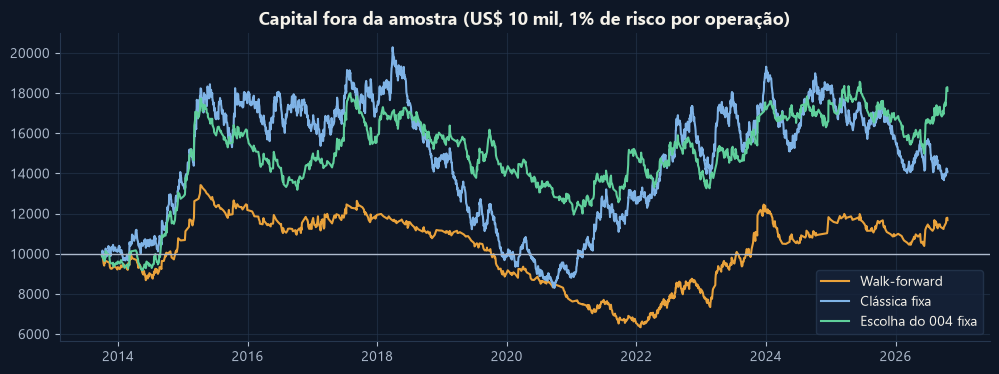

,trades,R médio,total R,máx. DD %
ano,,,,
2013,21,-0.324,-6.799,-6.905
2014,82,0.173,14.221,-12.450
2015,57,0.248,14.108,-12.157
2016,59,-0.080,-4.734,-9.576
2017,74,0.053,3.948,-8.403
2018,49,-0.134,-6.571,-10.080
2019,63,-0.326,-20.537,-20.459
2020,60,-0.264,-15.850,-17.717
2021,105,-0.147,-15.453,-15.298


,trades,R médio,total R
lado,,,
compra,535,-0.037,-19.781
venda,517,0.086,44.544


Sensibilidade: com comissão de US$ 7/lote, a expectativa do walk-forward vai de +0.024 para -0.008 R


In [8]:
CFG_004 = dict(inicio_faixa=3, entrada="ordem stop", stop="lado oposto", alvo_r=0.0, faixa="todas", tendencia="a favor do H4")
FIM_REC = FIM_WF + pd.Timedelta(hours=1)
ref = {"Walk-forward": TR_WF,
       "Clássica fixa": recorte(TRADES[NOME_PADRAO], INI_WF, FIM_REC),
       "Escolha do 004 fixa": recorte(TRADES[nome(CFG_004)], INI_WF, FIM_REC)}
RES_WF = pd.DataFrame({k: metricas(v, INI_WF, FIM_WF) for k, v in ref.items()})
display(RES_WF.round(3))

fig, ax = plt.subplots(figsize=(12, 4))
for (k, tr), cor in zip(ref.items(), [CORES["primaria"], CORES["secundaria"], CORES["positivo"]]):
    t_ = tr.sort_values("saida")
    ax.plot(t_["saida"], 10_000 * (1 + RISCO_POR_TRADE * t_["R"]).cumprod(), color=cor, label=k)
ax.axhline(10_000, color=CORES["texto_suave"], lw=1)
ax.set_title("Capital fora da amostra (US$ 10 mil, 1% de risco por operação)")
ax.legend()
plt.show()

T_WF = TR_WF.assign(ano=TR_WF["entrada"].dt.year, lado=np.where(TR_WF["direcao"] == 1, "compra", "venda"))
for col in ["ano", "lado"]:
    q = T_WF.groupby(col)["R"].agg(["count", "mean", "sum"]).rename(columns={"count": "trades", "mean": "R médio", "sum": "total R"})
    if col == "ano":
        q["máx. DD %"] = T_WF.groupby(col)["R"].apply(dd_ano)
    display(q.round(3))

# comissão de US$ 7/lote: cada combinação escolhida rodada de novo com comissão, nas mesmas janelas
com = pd.concat([recorte(rodar(TF, comissao=7.0, **CFG[esc]), t_fim, x_fim)
                 for (t_ini, t_fim, x_fim), esc in zip(JANELAS, WF["escolhida"])])
print(f"Sensibilidade: com comissão de US$ 7/lote, a expectativa do walk-forward vai de "
      f"{TR_WF['R'].mean():+.3f} para {com['R'].mean():+.3f} R")

## 7. Walk-forward contra o acaso

Repetimos o walk-forward inteiro trocando a direção de cada operação por cara ou coroa (mesmas combinações escolhidas,
mesmos dias, mesmos stops). Se o resultado real não for melhor que a maioria das simulações, o rompimento não carrega
informação de direção.

In [9]:
rng = np.random.default_rng(SEED)
n_barras = len(D[TF]["c"])
sims = []
for _ in range(N_SIM):
    inv = rng.choice(np.array([1, -1], np.int64), n_barras)
    cache, partes = {}, []
    for (t_ini, t_fim, x_fim), esc in zip(JANELAS, WF["escolhida"]):
        if esc not in cache:
            cache[esc] = rodar(TF, inv=inv, **CFG[esc])
        partes.append(recorte(cache[esc], t_fim, x_fim)["R"])
    sims.append(pd.concat(partes).mean())
sims = np.array(sims)
EXP_WF = TR_WF["R"].mean()
P_VALOR = float(np.mean(sims >= EXP_WF))
print(f"Walk-forward: {EXP_WF:+.3f} R | direção aleatória: média {sims.mean():+.3f} R "
      f"(p5 {np.percentile(sims, 5):+.3f}, p95 {np.percentile(sims, 95):+.3f}) | p-valor = {P_VALOR:.3f}")

Walk-forward: +0.024 R | direção aleatória: média -0.030 R (p5 -0.091, p95 +0.031) | p-valor = 0.077


## 8. PBO — probabilidade de sobreajuste

Método CSCV (Bailey et al.): dividimos os 16 anos em 10 blocos e testamos todas as 252 formas de usar metade dos blocos
como treino e a outra metade como teste. Em cada uma, vemos em que posição a campeã do treino fica no teste.
**PBO** = fração das vezes em que ela fica **abaixo da mediana**. Abaixo de 0,5 é o mínimo aceitável.

In [10]:
limites = pd.date_range(D[TF]["idx"][0], D[TF]["idx"][-1], periods=N_BLOCOS_PBO + 1)
SOMA = np.zeros((N_BLOCOS_PBO, len(NOMES)))
CONT = np.zeros_like(SOMA)
for j, n in enumerate(NOMES):
    tr = TRADES[n]
    b = np.clip(np.searchsorted(limites, tr["entrada"].to_numpy(), side="right") - 1, 0, N_BLOCOS_PBO - 1)
    SOMA[:, j] = np.bincount(b, weights=tr["R"].to_numpy(), minlength=N_BLOCOS_PBO)
    CONT[:, j] = np.bincount(b, minlength=N_BLOCOS_PBO)
logits = []
for treino in combinations(range(N_BLOCOS_PBO), N_BLOCOS_PBO // 2):
    teste = [k for k in range(N_BLOCOS_PBO) if k not in treino]
    exp_tr = SOMA[list(treino)].sum(0) / np.maximum(CONT[list(treino)].sum(0), 1)
    exp_te = SOMA[teste].sum(0) / np.maximum(CONT[teste].sum(0), 1)
    campea = np.argmax(exp_tr)
    pos = (np.argsort(np.argsort(exp_te))[campea] + 1) / (len(NOMES) + 1)
    logits.append(np.log(pos / (1 - pos)))
PBO = float(np.mean(np.array(logits) <= 0))
print(f"PBO = {PBO:.2f} ({len(logits)} combinações de blocos)")

PBO = 0.13 (252 combinações de blocos)


## 8.1 Ultra Low × Standard, lado a lado

O mesmo walk-forward nas duas contas, no período inteiro e **só de 2019 em diante** (onde o spread do Ultra Low é o
registrado de verdade, sem estimativa).

In [11]:
TR_STD = pd.read_csv(RAIZ / "backtests" / "004.1_rompimento_asia_wf_EURUSD_H1" / "operacoes_oos.csv",
                     parse_dates=["entrada", "saida"])
ini19 = pd.Timestamp("2019-01-01")
lado = pd.DataFrame({
    ("Período todo", "Standard"): metricas(TR_STD, INI_WF, FIM_WF),
    ("Período todo", "Ultra Low"): metricas(TR_WF, INI_WF, FIM_WF),
    ("2019 em diante", "Standard"): metricas(TR_STD, ini19, FIM_WF),
    ("2019 em diante", "Ultra Low"): metricas(TR_WF, ini19, FIM_WF),
})
display(lado.loc[["Nº trades", "Win rate %", "Expectativa R sem custos", "Expectativa R", "Fator de lucro",
                  "Retorno % (1% risco)", "Máx. drawdown %", "Sharpe", "Trades/semana"]].round(3))
custo_std = (TR_STD["R_bruto"] - TR_STD["R"]).mean()
custo_ul = (TR_WF["R_bruto"] - TR_WF["R"]).mean()
print(f"Custo médio por operação: Standard {custo_std:.3f} R | Ultra Low {custo_ul:.3f} R "
      f"({1 - custo_ul / custo_std:.0%} menor)")

Período todo           2019 em diante          
                             Standard Ultra Low       Standard Ultra Low
Nº trades                   1,069.000 1,052.000        724.000   710.000
Win rate %                     41.347    40.875         43.508    41.972
Expectativa R sem custos        0.105     0.075          0.113     0.069
Expectativa R                   0.020     0.024          0.023     0.015
Fator de lucro                  1.039     1.044          1.047     1.028
Retorno % (1% risco)           13.162    16.751         11.710     4.695
Máx. drawdown %               -48.441   -52.749        -31.735   -43.110
Sharpe                          0.136     0.155          0.174     0.107
Trades/semana                   1.569     1.544          1.777     1.743

Custo médio por operação: Standard 0.085 R | Ultra Low 0.051 R (40% menor)


## 9. Veredito

Os 7 critérios do laboratório aplicados ao **walk-forward**.

In [12]:
m = RES_WF["Walk-forward"]
dd_anos = T_WF.groupby("ano")["R"].apply(dd_ano)
criterios = pd.DataFrame([
    ("≥ 100 operações fora da amostra", f"{m['Nº trades']:.0f}", m["Nº trades"] >= 100),
    ("Expectativa > 0 R (líquida)", f"{m['Expectativa R']:+.3f}", m["Expectativa R"] > 0),
    ("Fator de lucro > 1,2", f"{m['Fator de lucro']:.2f}", m["Fator de lucro"] > 1.2),
    ("Melhor que aleatório (p < 0,05)", f"p = {P_VALOR:.3f}", P_VALOR < 0.05),
    ("PBO < 0,5", f"{PBO:.2f}", PBO < 0.5),
    ("Nenhum ano com DD > 20%", f"pior {dd_anos.min():.1f}%", dd_anos.min() > -20),
    (f"≥ {MIN_TRADES_SEMANA:g} trades/semana e p90 ≤ {MAX_INTERVALO_P90} dias úteis",
     f"{m['Trades/semana']:.1f}/sem · p90 {m['Intervalo p90 (dias úteis)']:.0f}",
     (m["Trades/semana"] >= MIN_TRADES_SEMANA) & (m["Intervalo p90 (dias úteis)"] <= MAX_INTERVALO_P90)),
], columns=["Critério", "Valor", "Passou"])
criterios["Passou"] = criterios["Passou"].map({True: "✅", False: "❌"})
display(criterios)
APROVADO = (criterios["Passou"] == "✅").all()
print("VEREDITO:", "✅ APROVADO" if APROVADO else
      f"❌ REPROVADO ({(criterios['Passou'] == '❌').sum()} de {len(criterios)} critérios falharam)")

,Critério,Valor,Passou
0,≥ 100 operações fora da amostra,1052,✅
1,Expectativa > 0 R (líquida),+0.024,✅
2,"Fator de lucro > 1,2",1.04,❌
3,"Melhor que aleatório (p < 0,05)",p = 0.077,❌
4,"PBO < 0,5",0.13,✅
5,Nenhum ano com DD > 20%,pior -20.5%,❌
6,≥ 2 trades/semana e p90 ≤ 5 dias úteis,1.5/sem · p90 8,❌


VEREDITO: ❌ REPROVADO (4 de 7 critérios falharam)


## 10. Salvar os resultados
Tudo vai para `backtests/004.2_rompimento_asia_ultralow_EURUSD_H1/`.

In [13]:
PASTA_BT = RAIZ / "backtests" / "004.2_rompimento_asia_ultralow_EURUSD_H1"
PASTA_BT.mkdir(parents=True, exist_ok=True)
params = {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, list, dict, tuple, type(None)))
          and k not in ("D", "TRADES", "CFG", "NOMES", "COMBOS", "JANELAS")}
(PASTA_BT / "parametros.json").write_text(json.dumps(params, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
WF.to_csv(PASTA_BT / "walkforward.csv", index=False)
RES_WF.to_csv(PASTA_BT / "metricas_oos.csv")
criterios.to_csv(PASTA_BT / "criterios.csv", index=False)
TR_WF.to_csv(PASTA_BT / "operacoes_oos.csv", index=False)
print(f"Salvo em {PASTA_BT}")

Salvo em C:\Dev\GitHub\LHS Capital\lhs-quant-lab\backtests\004.2_rompimento_asia_ultralow_EURUSD_H1


## 11. Conclusões

**Veredito: ❌ reprovado (4 de 7 critérios).** A conta Micro Ultra Low ajuda, mas não torna o setup aprovável.

1. **O custo cai 40%:** de 0,085 R para 0,051 R por operação (spread mediano de ~0,9 pip contra ~1,7 pip no Standard).
2. **As configurações fixas melhoram de verdade:**
   - regra clássica: de −0,012 R para **+0,019 R** (fator de lucro 0,98 → 1,04);
   - a escolha do 004 (a favor do H4): de +0,017 R para **+0,054 R** (fator de lucro 1,03 → **1,11**, drawdown −34%,
     Sharpe 0,39) — o melhor resultado do laboratório até agora, mas ainda abaixo do fator de lucro 1,2.
3. **O walk-forward quase não muda** (+0,020 → +0,024 R): com custo menor, a otimização passou a escolher combinações
   com vantagem bruta menor. Contra o acaso, o p-valor subiu para 0,077 (antes 0,017) e um ano passou de −20% (2019).
4. **O problema de fundo continua:** de 2019 a 2021 o setup perdeu três anos seguidos, e o drawdown do período inteiro
   passa de −50% com 1% de risco por operação.

**Conclusão:** com os custos da conta Micro Ultra Low, o rompimento da Ásia no H1 deixa de perder e passa a ganhar
pouco (+0,02 a +0,05 R por operação), mas a margem continua pequena demais (fator de lucro ≤ 1,11) e a sequência de
anos ruins é longa. **Não é vantajoso o suficiente para operar com dinheiro real.** Se for testar, apenas em conta
demo, com a configuração fixa do 004 (faixa 03h–10h, ordem stop, stop no lado oposto, sem alvo, a favor do H4).

## 12. Exercícios

1. Mude `TREINO_MESES` para 24 e `TESTE_MESES` para 3. Reotimizar mais vezes ajuda ou só segue o ruído?
2. Troque o critério de escolha no treino de "maior expectativa" para "maior fator de lucro". O resultado muda?
3. Fixe a combinação mais escolhida pelo walk-forward e rode só ela nos 16 anos. Ela é estável?